# Results

Every number here is read from `reports/`, written by the pipeline scripts (`run_pipeline.sh`).
Scores are OTTO Recall@20: `0.10 × clicks + 0.30 × carts + 0.60 × orders`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
COLS = ["clicks", "carts", "orders", "score"]


def load(name):
    return json.loads((REPORTS / name).read_text())


def table(results):
    return pd.DataFrame(results).T[COLS].astype(float).round(4)

## Data and split

In [2]:
summary = load("data_summary.json")
print(f"events: {summary['events']:,}")
print(f"test cutoff: {pd.to_datetime(summary['test_cutoff'], unit='s')} | "
      f"ranker-week cutoff: {pd.to_datetime(summary['rank_cutoff'], unit='s')}")
pd.DataFrame({"test week": summary["test_week"], "ranker week": summary["rank_week"]})

events: 216,716,096
test cutoff: 2022-08-21 22:00:00 | ranker-week cutoff: 2022-08-14 22:00:00


,test week,ranker week
sessions,1801251,2237925
with_click,1755489,2173551
with_carts,306859,385933
with_orders,151078,196717


## Main result (test week)

Baselines, the original two-stage system (v1, one blended list) and the final system
(v2: viewed-together candidates and a separate list per event type).

In [3]:
baselines = table(load("baselines_test_week.json")["results"])
systems = table(load("evaluation_test_week_v1_v2.json")["results"])
main = pd.concat([baselines, systems.loc[["v1, one blended list", "v2, separate list per type"]]])
main

,clicks,carts,orders,score
popular items only,0.0053,0.0067,0.0060,0.0061
session history + popular,0.3259,0.3122,0.5736,0.4704
history + bought-together + popular,0.4244,0.3831,0.6170,0.5276
"v1, one blended list",0.4730,0.4004,0.6282,0.5443
"v2, separate list per type",0.4968,0.4087,0.6327,0.5519


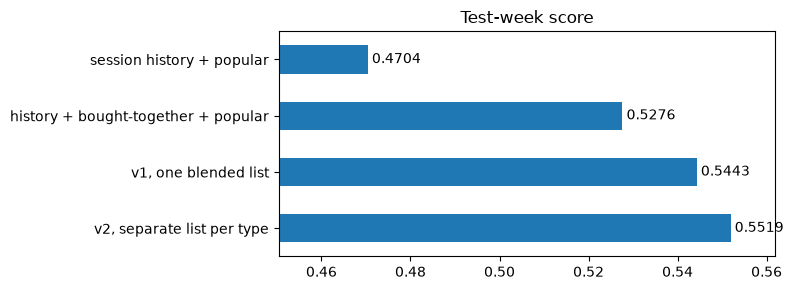

In [4]:
ax = main["score"].drop("popular items only").plot.barh(figsize=(8, 3), title="Test-week score")
ax.set_xlim(main["score"].drop("popular items only").min() - 0.02, main["score"].max() + 0.01)
for p in ax.patches:
    ax.annotate(f"{p.get_width():.4f}", (p.get_width(), p.get_y() + p.get_height() / 2), va="center", xytext=(3, 0),
                textcoords="offset points")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## From v1 to v2, one change at a time

1. Separate list per event type instead of one blended list.
2. Viewed-together candidates (items other shoppers viewed within 24 hours of the shopper's items).

In [5]:
systems

,clicks,carts,orders,score
"v1, one blended list",0.4730,0.4004,0.6282,0.5443
"v1, separate list per type",0.4833,0.4009,0.6282,0.5455
"v2, one blended list",0.4964,0.4080,0.6327,0.5517
"v2, separate list per type",0.4968,0.4087,0.6327,0.5519


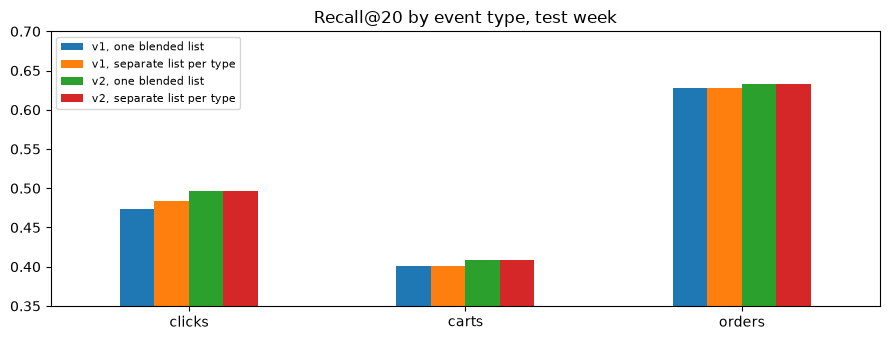

In [6]:
ax = systems[["clicks", "carts", "orders"]].T.plot.bar(figsize=(9, 3.5), rot=0, title="Recall@20 by event type, test week")
ax.set_ylim(0.35, 0.7)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Choosing on held-out ranker-week sessions

Every choice was made on ranker-week sessions the rankers never trained on, on two random samples,
before the test week was scored once. The ranking of the four systems should be the same on both samples.

In [7]:
held_out = pd.DataFrame({
    f"seed {seed}": table(load(f"evaluation_ranker_week_v1_v2_seed{seed}.json")["results"])["score"]
    for seed in (42, 7)
})
held_out["test week"] = systems["score"]
held_out

,seed 42,seed 7,test week
"v1, one blended list",0.6033,0.6062,0.5443
"v1, separate list per type",0.6040,0.6071,0.5455
"v2, one blended list",0.6102,0.6137,0.5517
"v2, separate list per type",0.6103,0.6142,0.5519


## What the v2 rankers rely on (share of LightGBM gain)

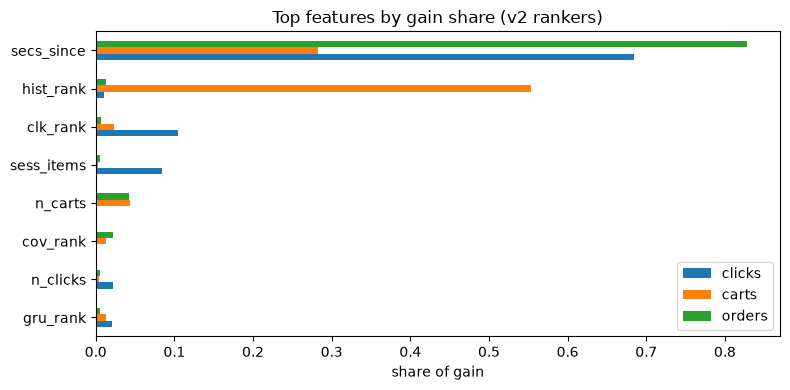

,clicks,carts,orders
secs_since,0.684,0.283,0.829
hist_rank,0.010,0.553,0.013
clk_rank,0.105,0.023,0.007
sess_items,0.084,0.004,0.006
n_carts,0.000,0.044,0.042
cov_rank,0.002,0.013,0.023
n_clicks,0.022,0.004,0.005
gru_rank,0.021,0.014,0.006


In [8]:
rankers = load("rankers_v2.json")["targets"]
gain = pd.DataFrame({t: r["gain_share"] for t, r in rankers.items()}).fillna(0)
top = gain.loc[gain.max(axis=1).sort_values(ascending=False).index[:8]]

ax = top.iloc[::-1].plot.barh(figsize=(8, 4), title="Top features by gain share (v2 rankers)")
ax.set_xlabel("share of gain")
plt.tight_layout()
plt.show()
top.round(3)

## GRU session model

In [10]:
gru = {week: load(f"gru_{week}.json") for week in ("rank", "test")}
pd.DataFrame.from_dict({week: {"sequences": g["sequences"], "batch": g["batch"], "lr": g["lr"],
                               "loss, last 500 steps": round(g["history"][-1]["last_500_steps_loss"], 3)}
                        for week, g in gru.items()}, orient="index")

,sequences,batch,lr,"loss, last 500 steps"
rank,7099054,1024,0.01,4.983
test,9716693,1024,0.01,4.834
